# Superstore Sales Analysis
## هل الشركة بتكسب ولا بتخسر؟ وفين بالظبط؟

## Introduction

الداتا دي بتاعة شركة Superstore، فيها مبيعات من 2014 لـ 2017.
فيها 9994 اوردر، في 4 مناطق، و 3 فئات رئيسية.
السؤال اللي بنجاوب عليه: الشركة بتكسب منين وبتخسر فين؟

In [31]:
import kagglehub
import pandas as pd
import os

# 1. تحميل الداتا
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
print("Path to dataset files:", path)

# 2. شوف ايه الملفات اللي نزلت
print(os.listdir(path))

# 3. اقرا ملف الـ CSV
# اسم الملف غالبا بيكون Sample - Superstore.csv
file_path = os.path.join(path, "Sample - Superstore.csv")
df = pd.read_csv(file_path, encoding='latin1')

# 4. اول نظرة على الداتا
print(f"Shape: {df.shape}")
print(df.head())
print(df.dtypes)
print(f"Duplicates: {df.duplicated().sum()}")
print(f"Nulls: {df.isnull().sum().sum()}")

Path to dataset files: C:\Users\asd\.cache\kagglehub\datasets\vivek468\superstore-dataset-final\versions\1
['Sample - Superstore.csv']
Shape: (9994, 21)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O

In [32]:
# الكشاف 1: شكل الداتا
print("=== 1. الشكل ===")
print(df.shape)

# الكشاف 2: اسامي الاعمدة
print("\n=== 2. اسامي الاعمدة ===")
print(df.columns.tolist())

# الكشاف 3: اول 3 صفوف بس
print("\n=== 3. اول 3 صفوف ===")
print(df.head(3))

=== 1. الشكل ===
(9994, 21)

=== 2. اسامي الاعمدة ===
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

=== 3. اول 3 صفوف ===
   Row ID        Order ID Order Date   Ship Date     Ship Mode Customer ID  \
0       1  CA-2016-152156  11/8/2016  11/11/2016  Second Class    CG-12520   
1       2  CA-2016-152156  11/8/2016  11/11/2016  Second Class    CG-12520   
2       3  CA-2016-138688  6/12/2016   6/16/2016  Second Class    DV-13045   

     Customer Name    Segment        Country         City  ... Postal Code  \
0      Claire Gute   Consumer  United States    Henderson  ...       42420   
1      Claire Gute   Consumer  United States    Henderson  ...       42420   
2  Darrin Van Huff  Corporate  United States  Los Angeles  ...       90036   

   Region       Product ID         Ca

In [33]:
# الكشاف 4: انواع البيانات والفراغات
print("=== انواع البيانات ===")
print(df.dtypes)

print("\n=== فيه فراغات؟ ===")
print(df.isnull().sum())

=== انواع البيانات ===
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

=== فيه فراغات؟ ===
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [34]:
# تحويل التاريخ من نص ل تاريخ حقيقي
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# نتأكد انه اتغير
print(df.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [35]:
# الكشاف 5: ملخص الارقام
print(df[['Sales', 'Quantity', 'Discount', 'Profit']].describe())

              Sales     Quantity     Discount       Profit
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001     3.789574     0.156203    28.656896
std      623.245101     2.225110     0.206452   234.260108
min        0.444000     1.000000     0.000000 -6599.978000
25%       17.280000     2.000000     0.000000     1.728750
50%       54.490000     3.000000     0.200000     8.666500
75%      209.940000     5.000000     0.200000    29.364000
max    22638.480000    14.000000     0.800000  8399.976000


In [36]:
# الكشاف 6: ايه انواع المنتجات اللي عندنا؟
print("=== Category ===")
print(df['Category'].value_counts())

print("\n=== Segment - نوع العميل ===")
print(df['Segment'].value_counts())

print("\n=== Region ===")
print(df['Region'].value_counts())

=== Category ===
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

=== Segment - نوع العميل ===
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

=== Region ===
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64


In [37]:
# الكشاف 7: مين بيكسبنا ومين بيخسرنا؟
print("=== الربح حسب نوع المنتج ===")
print(df.groupby('Category')['Profit'].sum())

print("\n=== الربح حسب نوع العميل ===")
print(df.groupby('Segment')['Profit'].sum())

print("\n=== الربح حسب المنطقة ===")
print(df.groupby('Region')['Profit'].sum())

=== الربح حسب نوع المنتج ===
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64

=== الربح حسب نوع العميل ===
Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64

=== الربح حسب المنطقة ===
Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


In [38]:
# الكشاف 8: الخصم والربح لكل منتج
print("=== متوسط الخصم لكل منتج ===")
print(df.groupby('Category')['Discount'].mean())

print("\n=== متوسط الربح في الاوردر الواحد ===")
print(df.groupby('Category')['Profit'].mean())

print("\n=== اكتر Sub-Category بتخسر ===")
print(df.groupby('Sub-Category')['Profit'].sum().sort_values().head(5))

=== متوسط الخصم لكل منتج ===
Category
Furniture          0.173923
Office Supplies    0.157285
Technology         0.132323
Name: Discount, dtype: float64

=== متوسط الربح في الاوردر الواحد ===
Category
Furniture           8.699327
Office Supplies    20.327050
Technology         78.752002
Name: Profit, dtype: float64

=== اكتر Sub-Category بتخسر ===
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


In [39]:
# الكشاف 9: نفتش في الترابيزات بس
tables = df[df['Sub-Category'] == 'Tables']

print(f"عدد اوردرات الترابيزات: {len(tables)}")
print(f"اجمالي المبيعات: {tables['Sales'].sum():,.0f}")
print(f"اجمالي الربح: {tables['Profit'].sum():,.0f}")
print(f"متوسط الخصم على الترابيزات: {tables['Discount'].mean()*100:.1f}%")
print(f"كام اوردر منهم خسران؟ {(tables['Profit'] < 0).sum()} من اصل {len(tables)}")
print("\n=== اكتر 5 ترابيزات خسرانة ===")
print(tables.sort_values('Profit').head(5)[['Product Name','Sales','Discount','Profit']])

عدد اوردرات الترابيزات: 319
اجمالي المبيعات: 206,966
اجمالي الربح: -17,725
متوسط الخصم على الترابيزات: 26.1%
كام اوردر منهم خسران؟ 203 من اصل 319

=== اكتر 5 ترابيزات خسرانة ===
                                           Product Name     Sales  Discount  \
9639  Chromcraft Bull-Nose Wood Oval Conference Tabl...  4297.644       0.4   
5320  Chromcraft Bull-Nose Wood Oval Conference Tabl...  2314.116       0.4   
8993                       Balt Solid Wood Round Tables  1875.258       0.4   
463   Bush Advantage Collection Racetrack Conference...  1272.630       0.5   
6639                      Hon 94000 Series Round Tables  1421.664       0.4   

         Profit  
9639 -1862.3124  
5320 -1002.7836  
8993  -968.8833  
463   -814.4832  
6639  -734.5264  


In [40]:
# لو الخصم اكتر من 30% اكتب "خصم عالي"، غير كده اكتب "خصم قليل"
tables['Discount_Level'] = ['خصم عالي' if x > 0.3 else 'خصم قليل' for x in tables['Discount']]

# اجمع الربح والمبيعات وعد الاوردرات لكل مجموعة
print(tables.groupby('Discount_Level')[['Sales','Profit']].sum())
print("\nعدد الاوردرات في كل مجموعة:")
print(tables['Discount_Level'].value_counts())

                     Sales      Profit
Discount_Level                        
خصم عالي         64774.390 -27295.8952
خصم قليل        142191.142   9570.4141

عدد الاوردرات في كل مجموعة:
Discount_Level
خصم قليل    197
خصم عالي    122
Name: count, dtype: int64


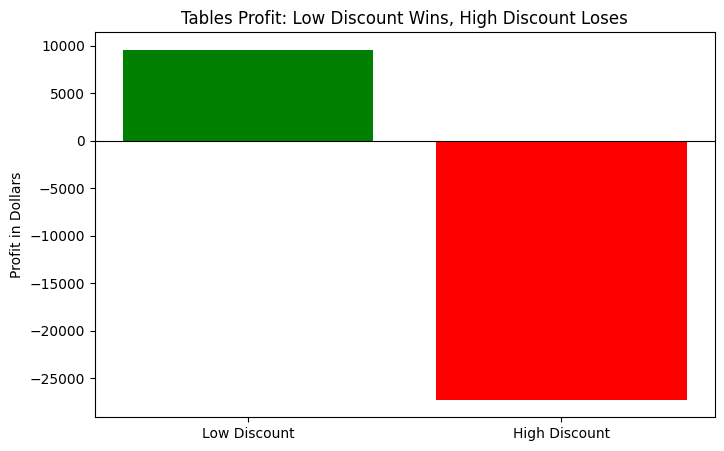

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(['Low Discount', 'High Discount'], [9570, -27295], color=['green', 'red'])
plt.title('Tables Profit: Low Discount Wins, High Discount Loses')
plt.ylabel('Profit in Dollars')
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

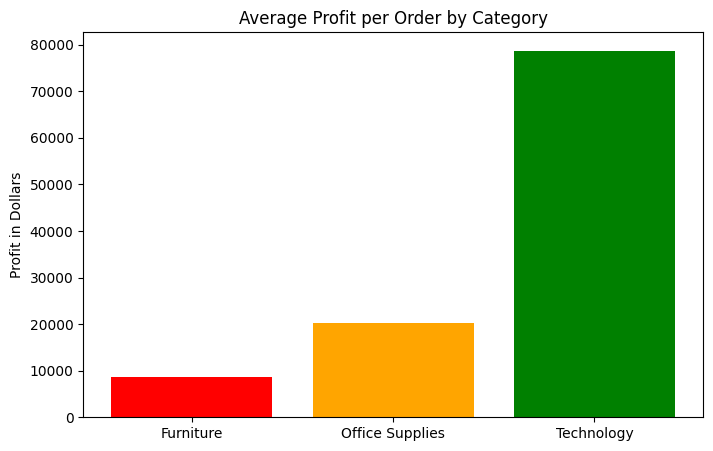

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(['Furniture', 'Office Supplies', 'Technology'], [8699, 20327, 78752], color=['red', 'orange', 'green'])
plt.title('Average Profit per Order by Category')
plt.ylabel('Profit in Dollars')
plt.show()

In [43]:
# لو شلنا الخصم العالي خالص، كنا هنكسب كام؟
profit_low_discount = 9570
loss_high_discount = -27295

total_current = profit_low_discount + loss_high_discount
total_if_no_high_discount = profit_low_discount

print(f"الربح الحالي من الترابيزات: {total_current}")
print(f"الربح لو لغينا الخصم العالي: {total_if_no_high_discount}")
print(f"الفرق اللي كنا هنوفره: {total_if_no_high_discount - total_current}")

الربح الحالي من الترابيزات: -17725
الربح لو لغينا الخصم العالي: 9570
الفرق اللي كنا هنوفره: 27295


In [44]:
# بنحسب عدد ايام الشحن = تاريخ الشحن - تاريخ الطلب
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# نشوف اول 5 صفوف
print(df[['Order Date', 'Ship Date', 'Shipping Days']].head())

  Order Date  Ship Date  Shipping Days
0 2016-11-08 2016-11-11              3
1 2016-11-08 2016-11-11              3
2 2016-06-12 2016-06-16              4
3 2015-10-11 2015-10-18              7
4 2015-10-11 2015-10-18              7


In [45]:
# تحليل الربح حسب عدد ايام الشحن
shipping_analysis = df.groupby('Shipping Days')['Profit'].agg(['mean', 'sum', 'count'])
print(shipping_analysis)

# نفس التحليل بس للترابيزات بس
tables_shipping = df[df['Sub-Category'] == 'Tables'].groupby('Shipping Days')['Profit'].agg(['mean', 'sum', 'count'])
print(tables_shipping)

                    mean         sum  count
Shipping Days                              
0              29.645411  15385.9685    519
1              20.436929   7541.2269    369
2              39.818676  53118.1143   1334
3              26.742208  26875.9187   1005
4              25.643394  71134.7742   2774
5              27.078471  58733.2045   2169
6              27.660821  33275.9677   1203
7              32.740494  20331.8469    621
                     mean        sum  count
Shipping Days                              
0              -53.782024 -1129.4225     21
1               54.712469   711.2621     13
2                1.570849    64.4048     41
3             -161.613689 -4525.1833     28
4              -41.552180 -3781.2484     91
5              -78.327414 -5717.9012     73
6              -72.848523 -2185.4557     30
7              -52.815314 -1161.9369     22


In [46]:
# 1. الربح حسب المنطقة
print("=== Region ===")
print(df.groupby('Region')['Profit'].agg(['mean', 'sum', 'count']))

# 2. الربح حسب نوع العميل
print("\n=== Segment ===")
print(df.groupby('Segment')['Profit'].agg(['mean', 'sum', 'count']))

# 3. الربح حسب طريقة الشحن
print("\n=== Ship Mode ===")
print(df.groupby('Ship Mode')['Profit'].agg(['mean', 'sum', 'count']))

# 4. الربح حسب السنة
df['Year'] = df['Order Date'].dt.year
print("\n=== Year ===")
print(df.groupby('Year')['Profit'].agg(['mean', 'sum', 'count']))

# 5. الربح حسب الـ Category
print("\n=== Category ===")
print(df.groupby('Category')['Profit'].agg(['mean', 'sum', 'count']))

# 6. الترابيزات بس حسب المنطقة
print("\n=== Tables by Region ===")
print(df[df['Sub-Category'] == 'Tables'].groupby('Region')['Profit'].agg(['mean', 'sum', 'count']))


=== Region ===
              mean          sum  count
Region                                
Central  17.092709   39706.3625   2323
East     32.135808   91522.7800   2848
South    28.857673   46749.4303   1620
West     33.849032  108418.4489   3203

=== Segment ===
                  mean          sum  count
Segment                                   
Consumer     25.836873  134119.2092   5191
Corporate    30.456667   91979.1340   3020
Home Office  33.818664   60298.6785   1783

=== Ship Mode ===
                     mean          sum  count
Ship Mode                                    
First Class     31.839948   48969.8399   1538
Same Day        29.266591   15891.7589    543
Second Class    29.535545   57446.6354   1945
Standard Class  27.494770  164088.7875   5968

=== Year ===
           mean         sum  count
Year                              
2014  24.858994  49543.9741   1993
2015  29.314274  61618.6037   2102
2016  31.617771  81795.1743   2587
2017  28.212340  93439.2696   3312


In [47]:
# 10. الربح حسب الولاية - للمشروع كله
print("=== State ===")
print(df.groupby('State')['Profit'].agg(['mean', 'sum', 'count']).sort_values('sum'))

# 11. الربح حسب المدينة - اسوأ 10 و احسن 10
print("\n=== City - Worst 10 ===")
print(df.groupby('City')['Profit'].agg(['mean', 'sum', 'count']).sort_values('sum').head(10))

print("\n=== City - Best 10 ===")
print(df.groupby('City')['Profit'].agg(['mean', 'sum', 'count']).sort_values('sum', ascending=False).head(10))



=== State ===
                            mean         sum  count
State                                              
Texas                 -26.121174 -25729.3563    985
Ohio                  -36.186304 -16971.3766    469
Pennsylvania          -26.507598 -15559.9603    587
Illinois              -25.625787 -12607.8870    492
North Carolina        -30.083985  -7490.9122    249
Colorado              -35.867351  -6527.8579    182
Tennessee             -29.189583  -5341.6936    183
Arizona               -15.303235  -3427.9246    224
Florida                -8.875461  -3399.3017    383
Oregon                 -9.600569  -1190.4705    124
Wyoming               100.196000    100.1960      1
West Virginia          46.480400    185.9216      4
North Dakota           32.878529    230.1497      7
South Dakota           32.902358    394.8283     12
Maine                  56.810775    454.4862      8
Idaho                  39.367767    826.7231     21
Kansas                 34.851813    836.4435     2

In [48]:
print(df.groupby('Product Name')['Profit'].agg(['mean', 'sum', 'count']).sort_values('sum').head(10))

                                                           mean        sum  \
Product Name                                                                 
Cubify CubeX 3D Printer Double Head Print          -2959.990133 -8879.9704   
Lexmark MX611dhe Monochrome Laser Printer          -1147.493250 -4589.9730   
Cubify CubeX 3D Printer Triple Head Print          -3839.990400 -3839.9904   
Chromcraft Bull-Nose Wood Oval Conference Table...  -575.223120 -2876.1156   
Bush Advantage Collection Racetrack Conference ...  -276.342514 -1934.3976   
GBC DocuBind P400 Electric Binding System           -313.027700 -1878.1662   
Cisco TelePresence System EX90 Videoconferencin... -1811.078400 -1811.0784   
Martin Yale Chadless Opener Electric Letter Opener  -216.530600 -1299.1836   
Balt Solid Wood Round Tables                        -300.264525 -1201.0581   
BoxOffice By Design Rectangular and Half-Moon M...  -382.812500 -1148.4375   

                                                    count  
Pro

# 📉 Part 1: What Makes Us Lose Money?

في الجزء ده هنعرض الرسومات اللي بتوضح الشركة بتخسر فين بالظبط.
الهدف هنا مش اننا نقول الشركة وحشة، بالعكس الشركة بتكسب،
بس الخسارة مركزة في حتت معينة، ولو حليناها الربح هيزيد جدا.

هنشوف 4 حاجات:
1. اسوأ الولايات اللي بتخسرنا
2. اسوأ المدن اللي بتخسرنا
3. اسوأ المنتجات اللي بتخسرنا
4. الترابيزات بتخسر في انهي منطقة



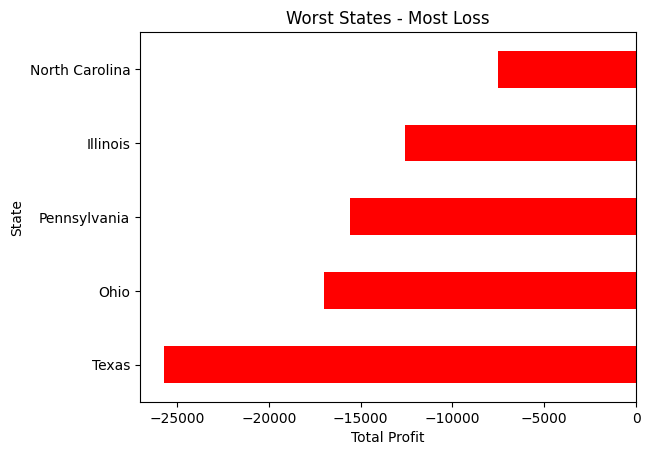

In [49]:
# بنجيب الربح حسب الولاية، وبنرتب من الاصغر للاكبر، وبناخد اول 5 بس
worst_states = df.groupby('State')['Profit'].sum().sort_values().head(5)

# بنرسمهم
worst_states.plot(kind='barh', color='red')
plt.title('Worst States - Most Loss')
plt.xlabel('Total Profit')
plt.show()

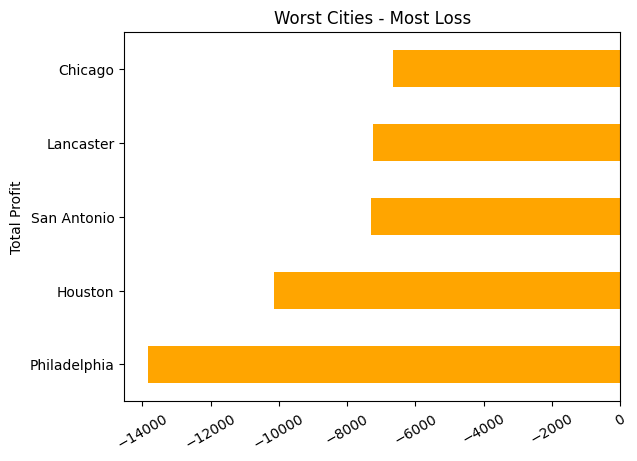

In [50]:
worst_cities = df.groupby('City')['Profit'].sum().sort_values().head(5)

worst_cities.plot(kind='barh', color='orange')
plt.title('Worst Cities - Most Loss')
plt.ylabel('Total Profit')
plt.xticks(rotation=30) # بنميل اسماء المدن عشان متدخلش في بعض
plt.show()

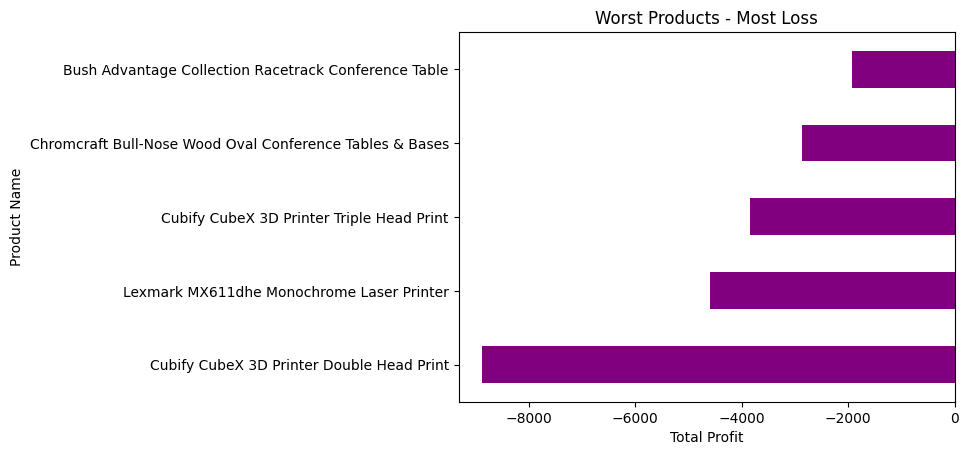

In [51]:
# بنجيب الربح حسب اسم المنتج، وبنرتب من الاصغر للاكبر، وبناخد اول 5 بس
worst_products = df.groupby('Product Name')['Profit'].sum().sort_values().head(5)

# بنرسمهم
worst_products.plot(kind='barh', color='purple')
plt.title('Worst Products - Most Loss')
plt.xlabel('Total Profit')
plt.show()

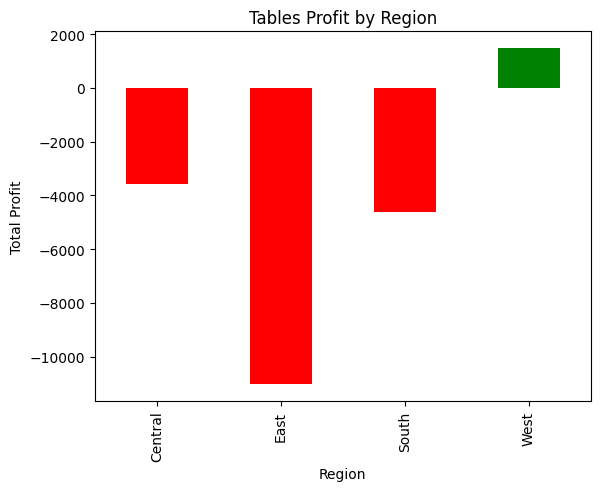

In [52]:
# الاول بنفلتر الترابيزات بس
tables = df[df['Sub-Category'] == 'Tables']

# بعدها بنجيب الربح بتاع الترابيزات حسب المنطقة
tables_by_region = tables.groupby('Region')['Profit'].sum()

# بنرسمهم
tables_by_region.plot(kind='bar', color=['red', 'red', 'red', 'green'])
plt.title('Tables Profit by Region')
plt.ylabel('Total Profit')
plt.show()

# 📈 Part 2: What Makes Us Win Money?

بعد ما شوفنا الخسارة فين، دلوقتي هنشوف الشركة بتكسب منين.
الشركة اصلا ناجحة وبتكبر كل سنة، والمكسب جاي من حتت معينة
لو ركزنا عليها اكتر، الربح هيزيد اكتر.

هنشوف 4 حاجات:
1. احسن الولايات اللي بتكسبنا
2. احسن المدن اللي بتكسبنا
3. احسن الفئات اللي بتكسبنا
4. الشركة بتكبر ازاي كل سنة

كل الرسومات اللي جاية دي باللون الاخضر، لانها مكسب.

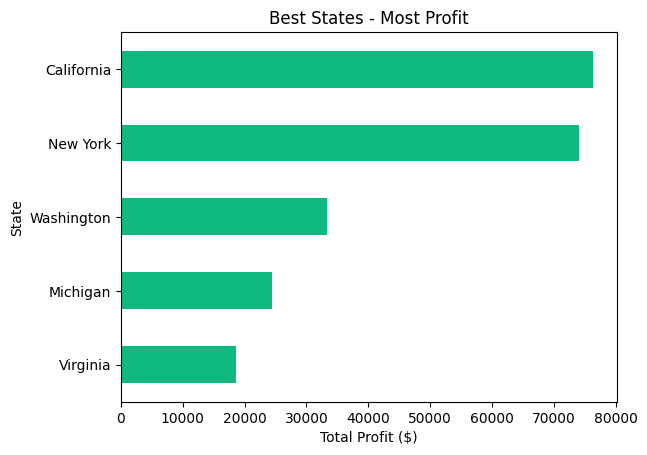

In [53]:
# احسن 5 ولايات
best_states = df.groupby('State')['Profit'].sum().sort_values(ascending=False).head(5)

best_states.plot(kind='barh', color='#10B981')
plt.title('Best States - Most Profit')
plt.xlabel('Total Profit ($)')
plt.gca().invert_yaxis()
plt.show()

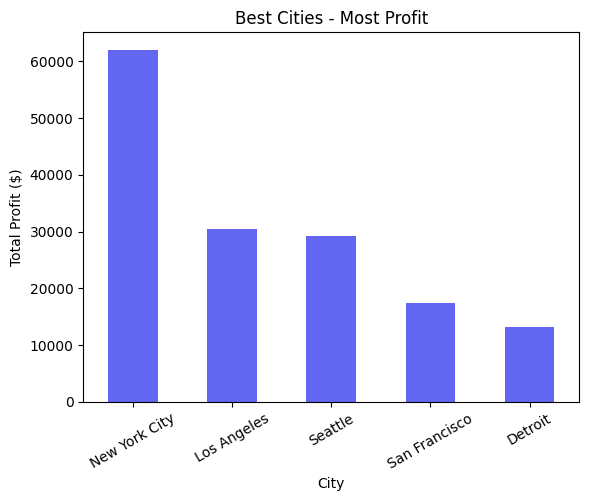

In [54]:
# احسن 5 مدن
best_cities = df.groupby('City')['Profit'].sum().sort_values(ascending=False).head(5)

best_cities.plot(kind='bar', color='#6366F1')
plt.title('Best Cities - Most Profit')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=30)
plt.show()

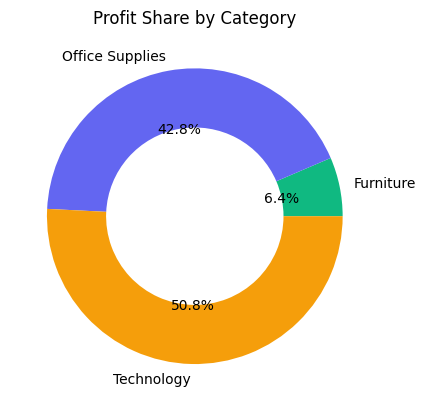

In [55]:
# الربح حسب الفئة
profit_by_category = df.groupby('Category')['Profit'].sum()

profit_by_category.plot(kind='pie', autopct='%1.1f%%', colors=['#10B981', '#6366F1', '#F59E0B'], wedgeprops={'width': 0.4})
plt.title('Profit Share by Category')
plt.ylabel('')
plt.show()

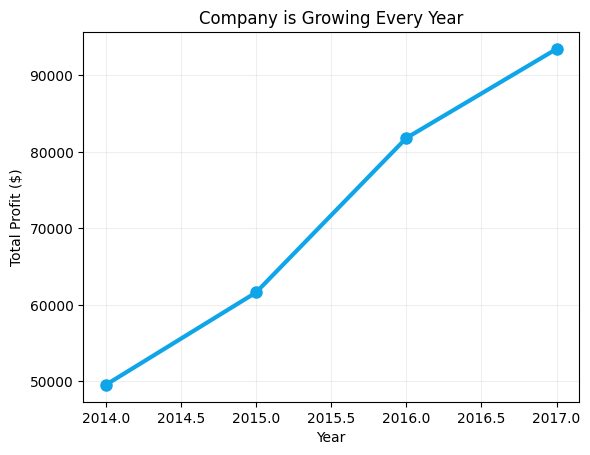

In [56]:
# الربح كل سنة
profit_by_year = df.groupby('Year')['Profit'].sum()

profit_by_year.plot(kind='line', marker='o', linewidth=3, color='#0EA5E9', markersize=8)
plt.title('Company is Growing Every Year')
plt.ylabel('Total Profit ($)')
plt.grid(alpha=0.2)
plt.show()

In [57]:
# حفظ الداتا بعد التعديلات
df.to_csv('Superstore_Clean.csv', index=False)

## الخلاصة

الشركة بتكسب وبتكبر كل سنة، من 49 الف لـ 93 الف.
المكسب جاي من كاليفورنيا و نيويورك و التكنولوجيا.
والخسارة مركزة في تكساس و فيلادلفيا و طابعة كيوبيفاي والترابيزات.
لو حلينا الخساير دي، الربح هيزيد اكتر بكتير.